# Comparación de modelos — deforestación en municipios rurales (2025)

Compara los tres modelos de clasificación de la carpeta `modelos y clusters/`
(gradient boosting, random forest, regresión logística) sobre el **mismo
conjunto de prueba (2025)**. **No incluye `segmentacion_municipios.ipynb`**
(clúster, a cargo de otra persona).

## Cómo funciona este notebook — por qué no es una "foto"

Para cada modelo, este notebook intenta, en este orden:

1. **Recalcular en vivo**: carga el `.joblib` que ese modelo guarda en
   `datos/analisis/...` y lo evalúa contra un conjunto de prueba reconstruido
   ejecutando, en este mismo notebook, las celdas de preparación de datos
   del notebook original (`gradient_boosting.ipynb`, `random_forest.ipynb`,
   `regresion_logistica.ipynb`) — no una copia pegada del código, sino las
   celdas de ESOS archivos tal como están en disco en el momento de correr
   esto. Si alguien cambia esa preparación de datos, este notebook la sigue
   automáticamente.
2. **Si el `.joblib` no existe todavía en este computador** (hoy es el caso
   de random forest y regresión logística — sus carpetas de salida están en
   `.gitignore` y solo existen en el computador donde se corrieron), cae de
   vuelta a **leer la tabla que ese mismo notebook ya calculó** la última
   vez que se ejecutó (sus propias secciones "Comparación de modelos"), leída
   directamente del archivo `.ipynb` tal como está hoy en disco.

En ambos casos, **volver a correr este notebook después de que alguien
actualice uno de los tres notebooks base trae los números nuevos** — en el
primer caso porque se recalcula desde cero, en el segundo porque se vuelve a
leer el archivo. Lo único que *no* se recalcula en vivo es la importancia de
variables por actividad productiva (sección 6): recalcularla implicaría
repetir permutaciones costosas (30 repeticiones) para cada modelo en cada
corrida de este notebook, así que esa sección sí depende de que cada
notebook se haya corrido recientemente — se explica de nuevo allí.

**Umbral de decisión: 0,5** para los tres modelos (convención documentada en
los propios notebooks de random forest y regresión logística).


## 0. Preparación del entorno


In [1]:
import json
import os
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (average_precision_score, confusion_matrix, roc_auc_score,
                              roc_curve, precision_recall_curve)

warnings.filterwarnings("ignore")

RAIZ = Path.cwd().resolve()
while not (RAIZ / "main_local.py").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

DIR_MODELOS = RAIZ / "modelos y clusters"
DIR_RESULTADOS = DIR_MODELOS / "resultados"
DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)

RUTA_GB = DIR_MODELOS / "gradient_boosting.ipynb"
RUTA_RF = DIR_MODELOS / "random_forest.ipynb"
RUTA_RL = DIR_MODELOS / "regresion_logistica.ipynb"

UMBRAL = 0.5
print("Raíz del proyecto:", RAIZ)


Raíz del proyecto: C:\Users\busta\trabajo_de_grado_ofr


In [2]:
# --- Utilidades para leer celdas y tablas ya calculadas directamente de un
# .ipynb en disco, SIN ejecutarlo (así nunca se repiten celdas costosas de
# entrenamiento; solo se leen outputs que el notebook ya calculó).

def celdas_fuente(ruta):
    """Lista con el código/texto fuente de cada celda de un notebook, en orden."""
    nb = json.load(open(ruta, encoding="utf-8"))
    return [{"tipo": c["cell_type"], "fuente": "".join(c.get("source", [])), "salidas": c.get("outputs", [])}
            for c in nb["cells"]]


import builtins
import contextlib

_open_original = builtins.open


def _open_utf8_por_defecto(file, mode="r", buffering=-1, encoding=None, *args, **kwargs):
    if encoding is None and "b" not in mode:
        encoding = "utf-8"
    return _open_original(file, mode, buffering, encoding, *args, **kwargs)


@contextlib.contextmanager
def forzar_utf8_en_open():
    """Las celdas 8 de random_forest.ipynb y regresion_logistica.ipynb abren
    gradient_boosting.ipynb con `open(ruta)`, SIN especificar codificación
    (es el código de esos notebooks, no de este). En Linux/Mac eso por
    defecto ya lee UTF-8 y no pasa nada, pero en Windows `open()` sin
    codificación usa la página de códigos del sistema (normalmente cp1252),
    que no sabe leer tildes/eñes en UTF-8 y revienta con UnicodeDecodeError.
    Mientras se ejecutan celdas de otros notebooks, se fuerza UTF-8 como
    codificación por defecto de `open()` -- sin modificar esos archivos."""
    builtins.open = _open_utf8_por_defecto
    try:
        yield
    finally:
        builtins.open = _open_original


def ejecutar_celdas(ruta, indices, ns):
    """Ejecuta, EN VIVO y en orden, un subconjunto de celdas de código de un
    notebook dentro del espacio de nombres `ns` -- tal como están en disco
    en este momento. Así el conjunto de prueba y las variables de cada
    modelo se reconstruyen con el código actual de cada notebook base, no
    con una copia pegada aquí."""
    celdas = celdas_fuente(ruta)
    with forzar_utf8_en_open():
        for i in indices:
            exec(compile(celdas[i]["fuente"], f"{ruta.name}:celda{i}", "exec"), ns)
    return celdas


from html.parser import HTMLParser as _HTMLParser


class _ParserTablaHTML(_HTMLParser):
    """Lee una tabla HTML simple (sin colspan/rowspan) celda por celda, sin
    depender de html5lib ni lxml -- paquetes que pd.read_html necesita y que
    pueden no estar instalados en este computador. Basta con lo que ya
    exportan los propios notebooks (tablas de pandas estándar)."""

    def __init__(self):
        super().__init__()
        self.en_thead = False
        self.fila = None
        self.celda = None
        self.filas_encabezado = []
        self.filas_cuerpo = []

    def handle_starttag(self, tag, attrs):
        if tag == "thead":
            self.en_thead = True
        elif tag == "tbody":
            self.en_thead = False
        elif tag == "tr":
            self.fila = []
        elif tag in ("th", "td"):
            self.celda = []

    def handle_endtag(self, tag):
        if tag == "tr" and self.fila is not None:
            (self.filas_encabezado if self.en_thead else self.filas_cuerpo).append(self.fila)
            self.fila = None
        elif tag in ("th", "td") and self.celda is not None:
            self.fila.append("".join(self.celda).strip())
            self.celda = None

    def handle_data(self, data):
        if self.celda is not None:
            self.celda.append(data)


def tabla_desde_html(html):
    """Convierte el HTML de una tabla de pandas (la que ya trae cada
    notebook en sus salidas) a un DataFrame. Un índice CON nombre (p. ej.
    "modelo") hace que pandas exporte un thead de dos filas: la fila 0 trae
    los nombres reales de columna, la fila 1 solo el nombre del índice (en
    la primera columna) y relleno en el resto -- se arma la columna 0 con
    ese nombre."""
    p = _ParserTablaHTML()
    p.feed(html)
    if not p.filas_cuerpo:
        return None
    if len(p.filas_encabezado) >= 2:
        columnas = list(p.filas_encabezado[0])
        columnas[0] = p.filas_encabezado[1][0]
    elif p.filas_encabezado:
        columnas = list(p.filas_encabezado[0])
    else:
        columnas = [f"col{i}" for i in range(len(p.filas_cuerpo[0]))]
    t = pd.DataFrame(p.filas_cuerpo, columns=columnas)
    for col in t.columns[1:]:
        try:
            t[col] = pd.to_numeric(t[col])
        except (ValueError, TypeError):
            pass
    return t


def tabla_de_salida(celda):
    """Si la celda tiene un resultado tabular (DataFrame mostrado como HTML),
    devuelve la ÚLTIMA tabla de ese tipo (la del `execute_result`, es decir
    la última expresión de la celda -- no una tabla impresa a mitad de celda
    con display())."""
    for out in reversed(celda["salidas"]):
        if out.get("output_type") == "execute_result" and "text/html" in out.get("data", {}):
            html = "".join(out["data"]["text/html"])
            t = tabla_desde_html(html)
            if t is not None:
                return t
    return None


def es_encabezado(fuente, texto_encabezado):
    """True si alguna LÍNEA de la celda es un encabezado markdown (empieza
    con '#') que contiene `texto_encabezado` -- para no confundir un
    encabezado de sección con una mención de paso en el texto (p. ej. en
    la introducción del notebook)."""
    return any(linea.strip().startswith("#") and texto_encabezado in linea
               for linea in fuente.split("\n"))


def tabla_tras_encabezado(celdas, texto_encabezado):
    """Busca la celda markdown cuyo ENCABEZADO de sección contiene
    `texto_encabezado` y devuelve la tabla de la primera celda de código
    que sigue con una salida tabular."""
    for i, c in enumerate(celdas):
        if c["tipo"] == "markdown" and es_encabezado(c["fuente"], texto_encabezado):
            for j in range(i + 1, len(celdas)):
                if celdas[j]["tipo"] == "markdown":
                    break  # se acabó la sección sin encontrar tabla
                t = tabla_de_salida(celdas[j])
                if t is not None:
                    return t
    return None


def tabla_por_columnas(celdas, columnas_exactas, contiene=None):
    """Busca, en TODAS las celdas de código, una tabla cuyas columnas
    (sin contar la primera, que es el índice re-leído desde HTML) sean
    exactamente `columnas_exactas` y (si se da) cuya primera columna
    contenga algún valor con la subcadena `contiene`. Útil cuando dos
    tablas comparten sección (como las dos tablas de importancia por
    bloque de random_forest.ipynb: por bloque temático y por actividad)."""
    columnas_exactas = set(columnas_exactas)
    for c in celdas:
        if c["tipo"] != "code":
            continue
        t = tabla_de_salida(c)
        if t is None or len(t.columns) < 2:
            continue
        resto = set(t.columns[1:])
        if resto != columnas_exactas:
            continue
        if contiene is None:
            return t
        if t.iloc[:, 0].astype(str).str.contains(contiene, regex=False).any():
            return t
    return None


def fila_por_subcadena(tabla, columna_indice, subcadena):
    """De una tabla ya leída (con la primera columna como índice en texto),
    devuelve la fila cuyo índice contiene `subcadena`."""
    serie = tabla[columna_indice].astype(str)
    coincide = tabla[serie.str.contains(subcadena, regex=False)]
    if len(coincide) == 0:
        return None
    return coincide.iloc[0]


def verificar_tabla(tabla, notebook, descripcion):
    """`tabla_por_columnas`/`tabla_tras_encabezado` devuelven None si la celda
    con esa tabla no tiene salida guardada -- lo más probable es que ese
    notebook base no se haya corrido completo (de principio a fin) la última
    vez. Sin este chequeo, el error siguiente es un AttributeError críptico
    sobre 'NoneType'; con él, el mensaje dice exactamente qué hacer."""
    if tabla is None:
        raise RuntimeError(
            f"No se encontró '{descripcion}' en las salidas guardadas de {notebook}. "
            f"Lo más probable es que ese notebook no se haya corrido completo (Run All) "
            f"la última vez -- esta sección LEE sus resultados ya calculados, no los "
            f"recalcula aquí. Corra {notebook} de principio a fin y vuelva a correr este "
            f"comparativo."
        )
    return tabla


## 1. Conjunto de evaluación común (2025)

Para que la comparación sea justa, los tres modelos se evalúan sobre
**exactamente las mismas 639 filas municipio-año de 2025**. En vez de
reconstruir esa muestra con una copia del código, se **ejecutan las propias
celdas de preparación de datos** de cada notebook base (desde el archivo
`.ipynb` tal como está en este momento en disco) dentro de un espacio de
nombres aislado para cada uno. Así, si alguien cambia cómo se construye una
variable en `random_forest.ipynb`, este notebook la recoge automáticamente
la próxima vez que se corra — no hay nada que mantener sincronizado a mano.

*Nota de compatibilidad:* las celdas de verificación de `random_forest.ipynb`
y `regresion_logistica.ipynb` abren `gradient_boosting.ipynb` con `open()`
sin especificar codificación; en Windows eso usa la página de códigos del
sistema y falla con tildes/eñes en UTF-8. Mientras se ejecutan esas celdas,
este notebook fuerza UTF-8 como codificación por defecto de `open()` (sin
modificar esos archivos) para que corra igual en Windows, Mac y Linux.


In [3]:
ns_gb, ns_rf, ns_rl = {}, {}, {}
ejecutar_celdas(RUTA_GB, [2, 4, 6, 8], ns_gb)
ejecutar_celdas(RUTA_RF, [2, 4, 6, 8, 10], ns_rf)
ejecutar_celdas(RUTA_RL, [2, 4, 6, 8, 10], ns_rl)

# Verificación cruzada: las tres muestras de prueba 2025 deben coincidir
# exactamente en (cod_dane, anio). RF y RL ya se verifican cada una contra
# GB dentro de su propia celda 8; aquí se repite el chequeo explícitamente
# para que quede documentado en ESTE notebook también.
s_gb = set(zip(ns_gb["test"].cod_dane.astype(str), ns_gb["test"].anio))
s_rf = set(zip(ns_rf["test"].cod_dane.astype(str), ns_rf["test"].anio))
s_rl = set(zip(ns_rl["test"].cod_dane.astype(str), ns_rl["test"].anio))
assert s_gb == s_rf == s_rl, "las muestras de prueba 2025 de los tres notebooks ya no coinciden"
print(f"Conjunto de prueba 2025 verificado: {len(s_gb)} municipios, idéntico en los tres notebooks.")


Filas: 3,852  ·  Municipios rurales: 642  ·  Años: [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Filas utilizables (2021-2025, con bosque): 3,195
Municipios-año con deforestación > 0: 2,019 (63.2 %)
Entrena (2021-2024): 2,556 filas, 31 departamentos
Prueba (2025): 639 filas
(6738, 28)
Pérdida de bosque (ha) en los municipio-año con tasa > 0:
count     2766.00
mean       220.01
std        985.41
min          0.06
10%          1.31
25%          3.62
50%         18.38
75%         94.25
max      17041.50
15 variables: 6 de credito, 5 de cosecha, bovinos, bosque y 2 categoricas
Filas: 3,195 | municipios: 639 | 0: 1,176 | 1: 2,019
Filas: 3,852  ·  Municipios rurales: 642  ·  Años: [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Filas utilizables (2021-2025, con bosque): 3,195
Municipios-año con deforestación > 0: 2,019 (63.2 %)
La muestra coincide exactamente con la del gradient boosting.
(673

## 2. Carga de los tres modelos

Para cada modelo se intenta primero cargar su `.joblib` guardado y evaluarlo
en vivo contra el conjunto de prueba reconstruido arriba. Si ese archivo no
existe todavía en este computador, se cae de vuelta a leer la fila que ese
mismo modelo ya reportó sobre sí mismo en la sección "Comparación de
modelos" de su propio notebook (AUC y matriz de confusión con umbral 0,5).
En cualquiera de los dos casos, las métricas de precisión/recall/F1/
especificidad/exactitud balanceada se calculan **aquí, de forma uniforme
para los tres modelos**, a partir de los conteos de la matriz de confusión
— así no dependen de cómo cada notebook nombró o calculó su propia versión
de esas métricas.


In [4]:
def metricas_de_confusion(tn, fp, fn, tp):
    precision = tp / (tp + fp) if (tp + fp) else np.nan
    recall = tp / (tp + fn) if (tp + fn) else np.nan
    especificidad = tn / (tn + fp) if (tn + fp) else np.nan
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else np.nan
    balanceada = (recall + especificidad) / 2
    return {"precisión": precision, "recall / sensibilidad": recall, "especificidad": especificidad,
            "F1": f1, "exactitud balanceada": balanceada}


def cargar_gb():
    ruta = DIR_RESULTADOS / "gradient_boosting_clasificador.joblib"
    y = ns_gb["test"].deforesta.values
    if ruta.exists():
        clf = joblib.load(ruta)
        prob = clf.predict_proba(ns_gb["test"][ns_gb["EXPLICATIVAS"]])[:, 1]
        pred = (prob >= UMBRAL).astype(int)
        tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
        return {"nombre": "Gradient boosting", "modo": "en vivo (.joblib recalculado)",
                "y_test": y, "prob_test": prob, "auc": roc_auc_score(y, prob),
                "ap": average_precision_score(y, prob), "tn": tn, "fp": fp, "fn": fn, "tp": tp}
    raise FileNotFoundError("no se encontró el .joblib de gradient boosting -- no debería pasar, es el modelo del equipo")


def cargar_desde_tabla_propia(ruta_nb, nombre_fila):
    '''Respaldo cuando el .joblib de ese modelo no existe en este computador:
    lee la fila que el PROPIO notebook calculó sobre sí mismo la última vez
    que se corrió.'''
    celdas = celdas_fuente(ruta_nb)
    t_auc = verificar_tabla(tabla_tras_encabezado(celdas, "Comparación de modelos: AUC"),
                             ruta_nb.name, "la tabla de comparación de modelos por AUC")
    t_cm = verificar_tabla(tabla_tras_encabezado(celdas, "matriz de confusión"),
                            ruta_nb.name, "la tabla de matrices de confusión")
    fila_auc = fila_por_subcadena(t_auc, t_auc.columns[0], nombre_fila)
    fila_cm = fila_por_subcadena(t_cm, t_cm.columns[0], nombre_fila)
    if fila_auc is None or fila_cm is None:
        raise ValueError(f"no se pudo leer la tabla de comparación propia de {ruta_nb.name} para '{nombre_fila}'")
    return {"auc": float(fila_auc["AUC-ROC"]), "tn": int(fila_cm["verdaderos negativos"]),
            "fp": int(fila_cm["falsos positivos"]), "fn": int(fila_cm["falsos negativos"]),
            "tp": int(fila_cm["verdaderos positivos"])}


def cargar_rf():
    ruta = RAIZ / "datos" / "analisis" / "modelo_random_forest_rural" / "modelo_random_forest.joblib"
    if ruta.exists():
        d = joblib.load(ruta)
        y = ns_rf["test"].deforesta.values
        prob = d["modelo"].predict_proba(ns_rf["test"][d["variables"]])[:, 1]
        pred = (prob >= d.get("umbral", UMBRAL)).astype(int)
        tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
        return {"nombre": "Random forest", "modo": "en vivo (.joblib recalculado)",
                "y_test": y, "prob_test": prob, "auc": roc_auc_score(y, prob),
                "ap": average_precision_score(y, prob), "tn": tn, "fp": fp, "fn": fn, "tp": tp}
    base = cargar_desde_tabla_propia(RUTA_RF, "RF por actividad")
    return {"nombre": "Random forest",
            "modo": "tabla ya calculada por random_forest.ipynb (no hay .joblib en este computador)",
            "y_test": None, "prob_test": None, "ap": None, **base}


def cargar_rl():
    ruta = RAIZ / "datos" / "analisis" / "modelo_logistico_rural" / "modelo_logistico.joblib"
    if ruta.exists():
        d = joblib.load(ruta)
        y = ns_rl["test"].deforesta.values
        prob = d["modelo"].predict_proba(ns_rl["test"][d["variables"]])[:, 1]
        pred = (prob >= d.get("umbral", UMBRAL)).astype(int)
        tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
        return {"nombre": "Regresión logística", "modo": "en vivo (.joblib recalculado)",
                "y_test": y, "prob_test": prob, "auc": roc_auc_score(y, prob),
                "ap": average_precision_score(y, prob), "tn": tn, "fp": fp, "fn": fn, "tp": tp}
    base = cargar_desde_tabla_propia(RUTA_RL, "Logística por actividad")
    return {"nombre": "Regresión logística",
            "modo": "tabla ya calculada por regresion_logistica.ipynb (no hay .joblib en este computador)",
            "y_test": None, "prob_test": None, "ap": None, **base}


modelos = {"Gradient boosting": cargar_gb(), "Random forest": cargar_rf(), "Regresión logística": cargar_rl()}
for nombre, m in modelos.items():
    print(f"{nombre:22s} | {m['modo']}")


Gradient boosting      | en vivo (.joblib recalculado)
Random forest          | en vivo (.joblib recalculado)
Regresión logística    | en vivo (.joblib recalculado)


## 3. Tabla comparativa de métricas (umbral = 0,5)

AUC-ROC y precisión promedio (AP) son independientes del umbral; el resto
se calcula con el umbral de decisión 0,5 que usan los tres modelos.


In [5]:
filas = []
for nombre, m in modelos.items():
    met = metricas_de_confusion(m["tn"], m["fp"], m["fn"], m["tp"])
    filas.append({"modelo": nombre, "AUC-ROC": m["auc"], "AP": m["ap"], **met,
                  "verdaderos negativos": m["tn"], "falsos positivos": m["fp"],
                  "falsos negativos": m["fn"], "verdaderos positivos": m["tp"], "fuente": m["modo"]})
tabla_metricas = pd.DataFrame(filas).set_index("modelo")
tabla_metricas.round(4)


,AUC-ROC,AP,precisión,recall / sensibilidad,especificidad,F1,exactitud balanceada,verdaderos negativos,falsos positivos,falsos negativos,verdaderos positivos,fuente
modelo,,,,,,,,,,,,
Gradient boosting,0.9278,0.9619,0.8780,0.8780,0.7817,0.8780,0.8299,179,50,50,360,en vivo (.joblib recalculado)
Random forest,0.9246,0.9594,0.8875,0.8659,0.8035,0.8765,0.8347,184,45,55,355,en vivo (.joblib recalculado)
Regresión logística,0.9047,0.9508,0.8606,0.8732,0.7467,0.8668,0.8099,171,58,52,358,en vivo (.joblib recalculado)


## 4. Curvas ROC y precisión-recall superpuestas


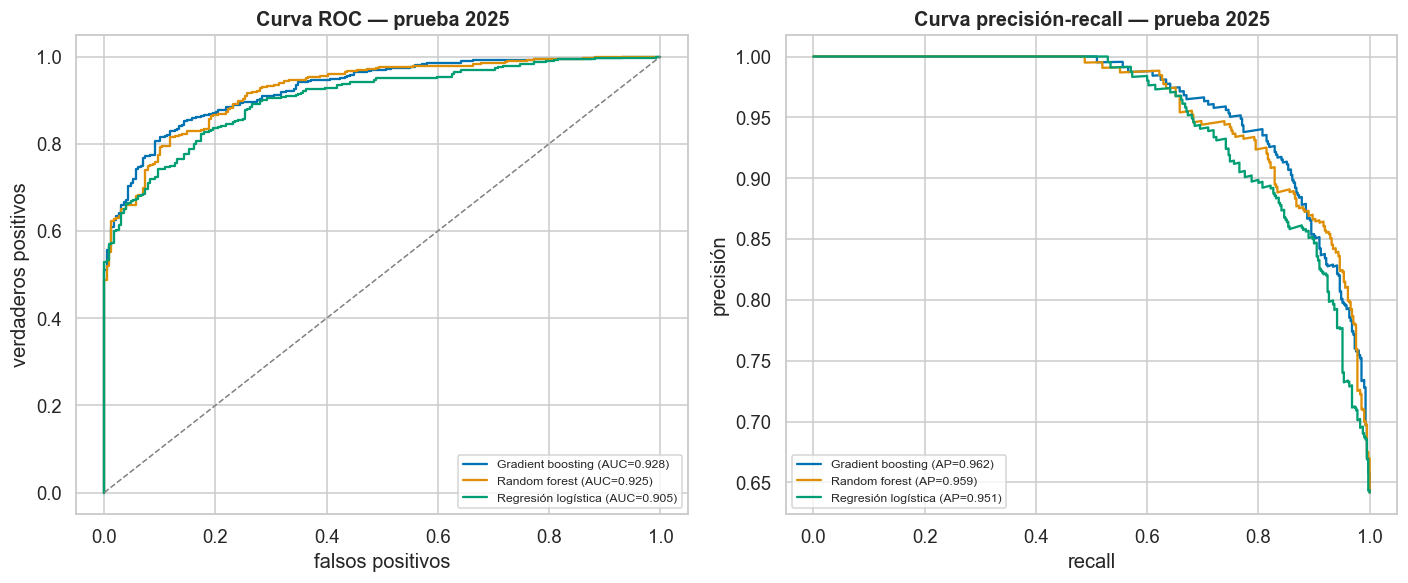

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
colores = {"Gradient boosting": "C0", "Random forest": "C1", "Regresión logística": "C2"}
omitidos = []
for nombre, m in modelos.items():
    if m["prob_test"] is None:
        omitidos.append(nombre)
        continue
    fpr, tpr, _ = roc_curve(m["y_test"], m["prob_test"])
    ax[0].plot(fpr, tpr, label=f"{nombre} (AUC={m['auc']:.3f})", color=colores[nombre])
    prec, rec, _ = precision_recall_curve(m["y_test"], m["prob_test"])
    ax[1].plot(rec, prec, label=f"{nombre} (AP={m['ap']:.3f})", color=colores[nombre])
ax[0].plot([0, 1], [0, 1], "--", color="grey", lw=1)
ax[0].set_xlabel("falsos positivos"); ax[0].set_ylabel("verdaderos positivos"); ax[0].set_title("Curva ROC — prueba 2025")
ax[1].set_xlabel("recall"); ax[1].set_ylabel("precisión"); ax[1].set_title("Curva precisión-recall — prueba 2025")
ax[0].legend(fontsize=8); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

if omitidos:
    print("Curva omitida (no hay .joblib en este computador, solo el AUC/AP de la tabla anterior): "
          + ", ".join(omitidos))


## 5. Matrices de confusión (umbral = 0,5)


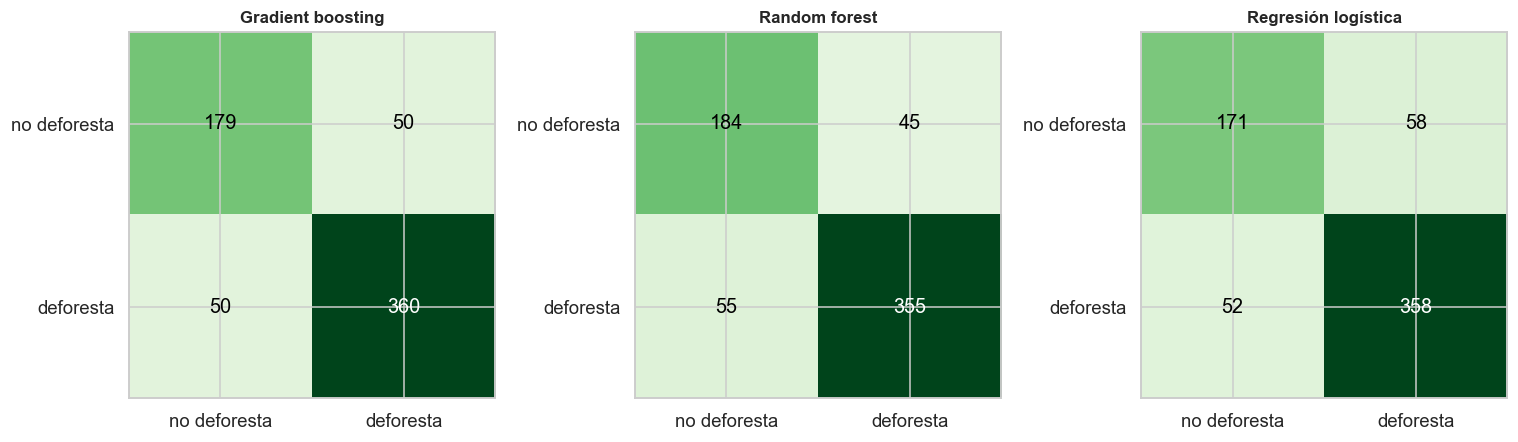

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4.3))
for eje, (nombre, m) in zip(ax, modelos.items()):
    cm = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
    eje.imshow(cm, cmap="Greens", vmin=0)
    umbral_color = cm.min() + (cm.max() - cm.min()) * 0.6
    for (i, j), v in np.ndenumerate(cm):
        color_texto = "white" if v > umbral_color else "black"
        eje.text(j, i, f"{v:,}", ha="center", va="center", fontsize=13, color=color_texto)
    eje.set_xticks([0, 1]); eje.set_xticklabels(["no deforesta", "deforesta"])
    eje.set_yticks([0, 1]); eje.set_yticklabels(["no deforesta", "deforesta"])
    eje.set_title(nombre, fontsize=11)
plt.tight_layout(); plt.show()


## 6. Importancia de variables por actividad productiva

**A diferencia de las secciones 3 a 5, esta sección no se recalcula en
vivo.** Recalcular la importancia por permutación de random forest y
regresión logística implicaría repetir 30 permutaciones por bloque dentro
de este mismo notebook cada vez que se corre -- lento, y redundante con lo
que cada notebook ya hace. En vez de eso, se **lee la tabla de importancia
por actividad que cada notebook ya calculó y guardó en su propia sección
de importancia**, directamente del archivo `.ipynb` tal como está hoy en
disco. Esto significa que esta sección específica sí depende de que cada
notebook base se haya corrido recientemente — si alguien cambia el modelo
y no lo vuelve a correr, esta sección seguirá mostrando la importancia de
la versión anterior (a diferencia de las secciones 3 a 5, que sí detectan
ese cambio apenas exista el `.joblib` nuevo).

Las tres medidas de importancia **no son comparables en magnitud** (caída
de AUC-ROC para random forest, % de participación en la suma de pesos para
la regresión logística, importancia de permutación cruda para gradient
boosting) — solo se compara el **orden relativo** de las actividades dentro
de cada modelo. Se muestran las **cinco cadenas productivas con variable
propia en los tres modelos** (ganadería, café, cacao, arroz, palma);
random forest y regresión logística además agrupan un bloque "otras
actividades" (crédito y cosecha residual) que gradient boosting no separa
de la misma forma, así que se deja fuera de esta comparación de a cinco
para no forzar una equivalencia que no existe.


In [8]:
# --- Random forest: tabla "por actividad productiva" (celda 25, última tabla)
celdas_rf_todas = celdas_fuente(RUTA_RF)
t_rf = verificar_tabla(
    tabla_por_columnas(celdas_rf_todas, {"n_variables", "caida_AUC", "sd"}, contiene="Ganadería"),
    "random_forest.ipynb", "la tabla de importancia por actividad productiva",
)
rf_actividad = t_rf.set_index(t_rf.columns[0])["caida_AUC"].rename(index=lambda s: s.split(" (")[0])

# --- Regresión logística: tabla "por actividad" (celda 31, última tabla)
celdas_rl_todas = celdas_fuente(RUTA_RL)
t_rl = verificar_tabla(
    tabla_por_columnas(celdas_rl_todas, {"participacion_%", "suma_pesos", "direccion_neta"}),
    "regresion_logistica.ipynb", "la tabla de participación por actividad",
)
rl_actividad = t_rl.set_index(t_rl.columns[0])["participacion_%"]

# --- Gradient boosting: no reporta "por actividad" directamente -- se agrega
# su importancia de permutación cruda (clasificación) por actividad con un
# mapeo explícito variable -> actividad (mismas actividades que RF/RL).
MAPA_ACTIVIDAD_GB = {
    "cred_gan": "Ganadería", "bovinos": "Ganadería",
    "cred_cafe": "Café", "cafe": "Café",
    "cred_cacao": "Cacao", "cacao": "Cacao",
    "cred_arroz": "Arroz", "arroz": "Arroz",
    "cred_palma": "Palma", "palma": "Palma",
}
imp_gb = pd.read_csv(DIR_RESULTADOS / "gradient_boosting_importancia_permutacion_clasificacion.csv")
# las etiquetas de la columna "variable" son el nombre legible (NOMBRES); se
# vuelve a mapear a la clave corta buscando coincidencia de inicio de cadena
NOMBRES_GB = ns_gb.get("NOMBRES", {})
etiqueta_a_clave = {v: k for k, v in NOMBRES_GB.items()}
imp_gb["clave"] = imp_gb["variable"].map(etiqueta_a_clave)
imp_gb["actividad"] = imp_gb["clave"].map(MAPA_ACTIVIDAD_GB)
gb_actividad = (imp_gb.dropna(subset=["actividad"])
                .assign(importancia_media=lambda d: d.importancia_media.clip(lower=0))
                .groupby("actividad")["importancia_media"].sum())

ACTIVIDADES_ORDEN = ["Ganadería", "Café", "Cacao", "Arroz", "Palma"]
comparacion_actividad = pd.DataFrame({
    "Gradient boosting (% de la importancia de actividad)": 100 * gb_actividad.reindex(ACTIVIDADES_ORDEN) / gb_actividad.reindex(ACTIVIDADES_ORDEN).sum(),
    "Random forest (% de la caída de AUC por actividad)": 100 * rf_actividad.reindex(ACTIVIDADES_ORDEN) / rf_actividad.reindex(ACTIVIDADES_ORDEN).sum(),
    "Regresión logística (% de participación por actividad)": 100 * rl_actividad.reindex(ACTIVIDADES_ORDEN) / rl_actividad.reindex(ACTIVIDADES_ORDEN).sum(),
})
comparacion_actividad.round(1)


,Gradient boosting (% de la importancia de actividad),Random forest (% de la caída de AUC por actividad),Regresión logística (% de participación por actividad)
Ganadería,36.4,35.3,3.5
Café,7.0,13.8,25.5
Cacao,50.4,49.9,48.9
Arroz,5.6,1.2,15.6
Palma,0.5,-0.2,6.5


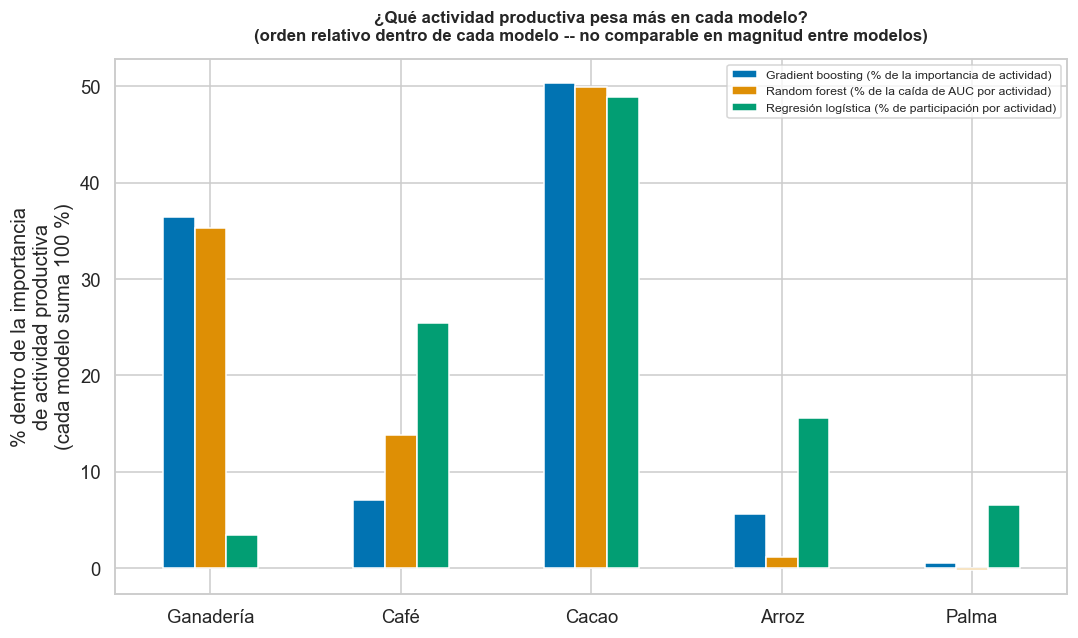

In [9]:
fig, ax = plt.subplots(figsize=(10, 6))
comparacion_actividad.plot(kind="bar", ax=ax, color=["C0", "C1", "C2"])
ax.set_ylabel("% dentro de la importancia\nde actividad productiva\n(cada modelo suma 100 %)")
ax.set_title("¿Qué actividad productiva pesa más en cada modelo?\n(orden relativo dentro de cada modelo -- no comparable en magnitud entre modelos)",
             fontsize=11, pad=12)
ax.legend(fontsize=8, loc="upper right")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 7. Gradient boosting también estima magnitud (¿cuánto?)

Random forest y regresión logística, en esta carpeta, solo responden
**¿va a deforestar?** (clasificación). Gradient boosting además entrena una
segunda etapa de **regresión** sobre la tasa de deforestación, condicionada
a que el municipio sí deforeste — una capacidad que los otros dos no
tienen hoy. Se lee directamente de `gradient_boosting_metricas.csv`
(la fuente ya estructurada que guarda el propio notebook).


In [10]:
met_gb = pd.read_csv(DIR_RESULTADOS / "gradient_boosting_metricas.csv")
met_gb[met_gb.modelo.str.contains("cuánto")][["métrica", "prueba_temporal_2025", "prueba_departamentos_fuera"]]


,métrica,prueba_temporal_2025,prueba_departamentos_fuera
7,R²,0.058732,0.050845
8,RMSE,4.362504,2.136554
9,error absoluto promedio (MAE),0.550571,0.408756
10,error absoluto mediano (MedAE),0.118289,0.148788
11,"R² excluyendo a Pedraza (diagnóstico, 5.3)",0.353710,NaN
12,"R² una sola regresión sin separar, solo donde ...",0.015857,NaN


## 8. Ventajas y desventajas

**Gradient boosting (equipo)**
- Ventajas: mejor AUC-ROC de los tres hoy; única capacidad de regresión
  (estima *cuánto*, no solo *si*); validación adicional dejando
  departamentos completos por fuera (menos optimista que una validación
  cruzada agrupada por municipio).
- Desventajas: menos interpretable directamente (requiere SHAP/importancia
  por permutación para explicar una predicción puntual); su R² en la etapa
  de regresión es bajo (cerca de 0,06-0,35 según el corte), es decir que
  *cuánto* deforesta es mucho más difícil de predecir que *si* deforesta.

**Random forest por actividad**
- Ventajas: AUC muy cercano al de gradient boosting; variables agrupadas
  por actividad productiva facilitan una lectura por sector (crédito +
  cosecha/bovinos de cada cadena); el modelo "de totales" (9 variables)
  confirma que separar por actividad no se queda muy por debajo de
  gradient boosting.
- Desventajas: sin capacidad de regresión; la importancia por bloques
  depende de permutación (más costosa de recalcular) y es menos directa de
  explicar a un no especialista que un coeficiente.

**Regresión logística por actividad**
- Ventajas: la más interpretable de las tres — cada coeficiente (y su
  *odds ratio*) tiene una lectura directa, con significancia estadística
  (errores robustos por clúster de municipio) y efectos marginales en
  puntos porcentuales; valiosa para sustentar criterios de debida
  diligencia regulatoria (p. ej. EUDR) donde hay que *justificar* por qué
  un crédito se marca como riesgoso, no solo predecirlo.
- Desventajas: el AUC más bajo de los tres modelos de clasificación (ver
  la tabla de la sección 3 para la cifra vigente); requiere eliminar
  variables correlacionadas (VIF) y supone una forma funcional (logit) que
  los modelos de árboles no necesitan asumir.


## 9. Veredicto


In [11]:
mejor_auc = tabla_metricas["AUC-ROC"].idxmax()
peor_auc = tabla_metricas["AUC-ROC"].idxmin()
brecha = tabla_metricas["AUC-ROC"].max() - tabla_metricas["AUC-ROC"].min()

print(f"Por AUC-ROC en la prueba 2025, el mejor modelo HOY es: {mejor_auc} "
      f"(AUC = {tabla_metricas.loc[mejor_auc, 'AUC-ROC']:.4f}), "
      f"seguido de cerca por los otros dos (brecha total de {brecha:.4f} puntos de AUC entre "
      f"el mejor y el peor, {peor_auc}).")


Por AUC-ROC en la prueba 2025, el mejor modelo HOY es: Gradient boosting (AUC = 0.9278), seguido de cerca por los otros dos (brecha total de 0.0230 puntos de AUC entre el mejor y el peor, Regresión logística).


No hay un único "mejor modelo" fuera de un AUC más alto — depende de la
pregunta:

- **Para priorizar/rankear municipios por riesgo** (el uso más directo del
  Observatorio): el modelo con mayor AUC-ROC hoy es el punto de partida
  natural, salvo que la diferencia con los demás sea pequeña frente al
  costo de mantenerlo (gradient boosting y random forest están reñidos;
  ver la tabla de la sección 3 para la cifra vigente).
- **Para justificar una decisión de crédito o una debida diligencia
  regulatoria** (donde hay que explicar *por qué*, no solo *cuánto*):
  la regresión logística es la opción más defendible, aun con un AUC algo
  menor, porque cada variable tiene un coeficiente, un *odds ratio* y una
  significancia estadística que se pueden citar directamente.
- **Para estimar la magnitud esperada de deforestación** (no solo si va a
  ocurrir): solo gradient boosting ofrece esa segunda etapa de regresión
  hoy -- random forest y regresión logística no tienen un equivalente en
  esta carpeta.

En la práctica, los tres modelos están de acuerdo en qué actividades
productivas pesan más (ver sección 6): eso es una señal de robustez del
hallazgo, más allá de qué modelo se use para el ranking final.


## 10. Síntesis: qué responde esta comparación de los objetivos y KPI del documento

Cada notebook de modelo ya tiene su propia síntesis de objetivos/KPI (ver, por ejemplo, la sección 9 de
`gradient_boosting.ipynb`). Esta sección no la repite: se enfoca en lo que **la comparación misma** aporta
por encima de cualquier notebook individual — sobre todo, evidencia convergente entre métodos
independientes y un argumento de interpretabilidad para sustentar un hallazgo frente a un interesado.

**Nota sobre alcance:** esta comparación incluye los tres modelos (gradient boosting, random forest y
regresión logística) porque así se pidió para este notebook puntual. La comparación OFICIAL del documento
final (Tabla 26/27) es solo gradient boosting y random forest, más una sección aparte de clustering — el
equipo decidió no incluir regresión logística ahí. Lo que sigue usa los tres modelos donde ayuda a sustentar
un objetivo o KPI, pero no debe leerse como que el documento reporta una comparación de tres modelos.


In [12]:
# Evidencia concreta (no una afirmación general) para CEN-6/ODM-3/CDM-5: se lee en vivo,
# del propio regresion_logistica.ipynb tal como está hoy en disco (sección 12, celda de
# coeficientes), el odds ratio y el p-valor de cacao -- la actividad que compara la sección 6.
t_coefs_rl = verificar_tabla(
    tabla_por_columnas(
        celdas_rl_todas,
        {"coef", "OR", "OR_IC95_inf", "OR_IC95_sup", "p_valor", "coef_sklearn", "signif"},
    ),
    "regresion_logistica.ipynb", "la tabla de coeficientes/odds ratio (sección 12)",
)
fila_cacao_credito = fila_por_subcadena(t_coefs_rl, t_coefs_rl.columns[0], "credito_cacao")
fila_cacao_cosecha = fila_por_subcadena(t_coefs_rl, t_coefs_rl.columns[0], "cosechada_cacao")

# ¿Las tres medidas de importancia por actividad (sección 6) coinciden en cuál pesa más?
top_por_modelo = comparacion_actividad.idxmax(axis=0)
coinciden_los_tres = top_por_modelo.nunique() == 1

print("Actividad con mayor participación relativa, por modelo (sección 6):")
print(top_por_modelo.to_string())
print(f"\n¿Coinciden los tres modelos? {'sí' if coinciden_los_tres else 'no'}\n")
print("Regresión logística, re-estimación con significancia (sección 12 de regresion_logistica.ipynb):")
print(f"  crédito a cacao  -> OR = {fila_cacao_credito['OR']}, p-valor = {fila_cacao_credito['p_valor']}")
print(f"  cosecha de cacao -> OR = {fila_cacao_cosecha['OR']}, p-valor = {fila_cacao_cosecha['p_valor']}")


Actividad con mayor participación relativa, por modelo (sección 6):
Gradient boosting (% de la importancia de actividad)      Cacao
Random forest (% de la caída de AUC por actividad)        Cacao
Regresión logística (% de participación por actividad)    Cacao

¿Coinciden los tres modelos? sí

Regresión logística, re-estimación con significancia (sección 12 de regresion_logistica.ipynb):
  crédito a cacao  -> OR = 1.381, p-valor = 0.008
  cosecha de cacao -> OR = 1.455, p-valor = 0.008


| Objetivo / KPI | Qué aporta esta comparación (más allá de cada notebook por separado) |
|---|---|
| **OBJ-N1** (capacidad analítica del Observatorio, más allá de solo deforestación) | Comparar tres métodos independientes y llegar a una recomendación razonada (sección 9) es, en sí, un caso de uso del Observatorio: no "un modelo", sino un proceso de validación cruzada entre modelos que se puede repetir con cualquier otro problema. |
| **CEN-1** (el interesado valida que el hallazgo tiene valor de negocio real) | Que tres modelos entrenados de forma muy distinta (árboles vs. coeficientes lineales) señalen la misma actividad productiva como la más asociada (celda anterior) es evidencia más fuerte para presentarle al interesado que el resultado de un solo modelo — es convergencia, no la lectura de un solo algoritmo. |
| **CEN-6** (el interesado explica, sin apoyo del equipo, por qué al menos una variable es relevante) | La regresión logística (sección 8 y celda anterior) es la única de las tres que entrega, para esa misma actividad, un *odds ratio* y un *p-valor* citables directamente — el tipo de cifra que permite a alguien ajeno al equipo justificar por qué una variable importa, sin apelar a "porque el modelo lo dice". |
| **ODM-3** (variables financieras/agropecuarias más asociadas con la deforestación) | La sección 6 compara las cinco cadenas productivas con variable propia en los tres modelos; que la misma actividad quede arriba en los tres (celda anterior) es la evidencia de ODM-3 con mayor respaldo metodológico de todo el proyecto, porque no depende de una sola técnica. |
| **CDM-5** (top 3 variables con asociación significativa, p < 0,05) | La celda anterior agrega una prueba de significancia estadística formal (errores robustos por clúster de municipio) para esa misma actividad, complementaria a la importancia por permutación que ya reporta `gradient_boosting.ipynb` en su propia sección 9/CDM-5 — dos pruebas de naturaleza distinta llegando a una conclusión compatible. |
| **CDM-6** (reproducibilidad) | Esta comparación es, en sí, una verificación adicional de reproducibilidad: la sección 1 reconstruye el conjunto de evaluación común desde cero en cada corrida y confirma que los tres notebooks coinciden en la muestra (mismos municipios/años); si algún notebook base cambiara su muestra sin querer, esta sección lo mostraría como un desacuerdo. |
| **CDM-7** (brecha entrenamiento-prueba ≤ 15 %, control de sobreajuste) | Solo gradient boosting reporta ese control con un segundo conjunto de prueba independiente (dejar departamentos completos por fuera; sección 7 de este comparativo, vía `gradient_boosting_metricas.csv`): 2,9 % en ambas evaluaciones, dentro del umbral. Random forest y regresión logística usan validación cruzada agrupada por municipio en la búsqueda de hiperparámetros, que cumple un papel parecido pero no es la misma prueba — esta comparación no inventa una cifra de brecha para los dos que no la reportan en esa forma. |

**Lo que esta comparación NO sustenta directamente:** igual que cada notebook de modelo por separado,
OBJ-N2 y CEN-4 (cierre comercial) — comparar modelos no genera una venta por sí mismo; lo que aporta es un
argumento más sólido (convergencia entre métodos) para que el Observatorio lo use en esa conversación.


## 11. Guardado


In [13]:
RUTA_SALIDA = DIR_RESULTADOS / "comparacion_modelos_metricas.csv"
tabla_metricas.to_csv(RUTA_SALIDA)
print("Guardado en", RUTA_SALIDA.relative_to(RAIZ))


Guardado en modelos y clusters\resultados\comparacion_modelos_metricas.csv
